# Miniproyecto 1 — Clasificación de imágenes de MRI cerebral con Redes Neuronales Convolucionales

**Curso:** Técnicas de Deep Learning
**Autores:** Alison Builes, Omar Fernando Muñoz y Julian Moreno Bohorquez

**Objetivo.** Desarrollar un método basado en CNN que clasifique cortes 2D extraídos de resonancias magnéticas (MRI) cerebrales en cuatro categorías: **glioma**, **meningioma**, **pituitario** y **sano** (sin tumor).

**Experimentos.** Para cumplir el objetivo se comparan tres configuraciones: una CNN y una ResNet18 preentrenada ajustada al problema, sin *data augmentation* y una con *data augmentation*.

| ID | Modelo | Inicialización | *Data augmentation* |
|---|---|---|---|
| A | CNN propia (5 bloques Conv-BN-ReLU-MaxPool) | Aleatoria | Sí |
| B | ResNet18 | Preentrenada en ImageNet (*fine-tuning*) | No |
| C | ResNet18 | Preentrenada en ImageNet (*fine-tuning*) | Sí |

**¿Por qué ResNet18?** Entre las arquitecturas vistas en el curso (LeNet, AlexNet, VGG, GoogLeNet, MobileNet, EfficientNet, ResNet y DenseNet) se eligió ResNet18 (He et al., 2016) por su equilibrio entre capacidad y costo. Con 11.2 M de parámetros es mucho más liviana que VGG16 (138 M) o AlexNet (61 M), lo que reduce el riesgo de sobreajuste con ~4600 imágenes y permite completar los 15 entrenamientos en una GPU T4; en imágenes médicas, además, las redes pequeñas preentrenadas obtienen resultados comparables a las grandes (Raghu et al., 2019). Sus conexiones residuales permiten un *fine-tuning* estable de toda la red y su entrada nativa de 224×224 coincide con el preprocesamiento. La justificación completa y sus limitaciones están en la sección 3.

## 0. Configuración del entorno

### 0.1 Instalación de dependencias

In [28]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


### 0.2 Librerías y dispositivo de cómputo

In [29]:
# --- Librerías estándar ---
import hashlib                                   # huellas MD5 para detectar duplicados
import json                                      # guardar resultados de cada corrida
import random
import shutil
import time
from concurrent.futures import ThreadPoolExecutor  # lectura de imágenes en paralelo
from pathlib import Path

# --- Análisis de datos y visualización ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import models                   # ResNet18 preentrenada
from torchvision.transforms import v2 as T       # data augmentation

# --- Métricas y partición ---
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split

# Dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"  # precisión mixta solo en GPU (acelera el entrenamiento)
print(f"PyTorch {torch.__version__} | dispositivo: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
if device.type != "cuda":
    print("ADVERTENCIA: no hay GPU.")

PyTorch 2.11.0+cu128 | dispositivo: cuda (Tesla T4)


### 0.3 Configuración general y funciones auxiliares

Se centralizan en el diccionario `CFG` los hiperparámetros comunes a todos los experimentos (resolución, partición, semillas, tamaño de *batch*, épocas, *weight decay*), para que se reporten en el informe tal como se usaron. Además se definen:

* **Carpetas de salida** para figuras y *checkpoints* (en Colab, `/content/resultados`; en Kaggle, `/kaggle/working/resultados`, la única carpeta que Kaggle permite descargar).
* **Estilo de figuras** con texto pequeño, pensado para un artículo a dos columnas.
* `save_fig`: guarda cada figura en PNG a 300 dpi.
* `set_seed`: fija las semillas de Python, NumPy y PyTorch para que cada corrida sea reproducible.

In [30]:
# ------------------------------------------------------------------------------------------
# Configuración e hiperparámetros generales
# ------------------------------------------------------------------------------------------
CFG = {
    "img_size": 224,               # resolución de entrada
    "split": (0.70, 0.15, 0.15),   # train / val / test
    "split_seed": 42,              # semilla de la partición
    "seeds": [0, 1, 2, 3, 4],      # semillas de entrenamiento -> media ± desviación estándar
    "batch_size": 32,
    "epochs": 25,                  # número máximo de épocas
    "patience": None,              
    "weight_decay": 1e-4,          # regularización L2 desacoplada (AdamW)
    "num_workers": 2,
    "max_images_per_class": None,  
}


# Carpeta de salida 

if Path("/kaggle/working").exists():
    OUT_DIR, CKPT_DIR = Path("/kaggle/working/resultados"), Path("/tmp/checkpoints")
elif Path("/content").exists():
    OUT_DIR = Path("/content/resultados")
    CKPT_DIR = OUT_DIR / "checkpoints"
else:
    OUT_DIR = Path("resultados")
    CKPT_DIR = OUT_DIR / "checkpoints"
FIG_DIR = OUT_DIR / "figuras"
for d in (FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Estilo de figuras
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 120, "savefig.dpi": 300})


def save_fig(fig, name):
    # Guarda la figura en PNG
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print("Figura guardada en", path)


def set_seed(seed):
    # Fija las semillas de Python, NumPy y PyTorch para que los experimentos sean reproducibles.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


torch.backends.cudnn.benchmark = True 

## 1. Exploración y preparación de los datos

**Dataset.** [rm1000/brain-tumor-mri-scans](https://www.kaggle.com/datasets/rm1000/brain-tumor-mri-scans) (Kaggle): 7023 cortes 2D de MRI cerebral en distintos planos. La clase de cada imagen se infiere del nombre de la carpeta que la contiene.

### 1.1 Descarga y estructura de carpetas

Se descarga el dataset con `kagglehub` y se recorre el árbol de carpetas para ver cómo está organizado y cuántas imágenes hay por clase.

**Observaciones.** Hay una carpeta por clase (`glioma`, `healthy`, `meningioma`, `pituitary`) y 7023 imágenes en total. Los nombres de archivo se repiten entre carpetas (p. ej. `0664.jpg` aparece en las cuatro), por lo que cada imagen se identifica por su ruta completa y no por su nombre.

In [31]:
import os
import kagglehub

# Descarga dataset
DATA_ROOT = Path(kagglehub.dataset_download("rm1000/brain-tumor-mri-scans"))
print(f"Ruta original de descarga: {DATA_ROOT}\n")

# árbol de directorios
def mostrar_arbol(ruta, max_archivos=3):
    total_imagenes_dataset = 0
    for root, dirs, files in os.walk(ruta):
        nivel = len(Path(root).relative_to(ruta).parts)
        indentacion = "  " * nivel
        nombre_dir = os.path.basename(root) or ". (Raíz del Dataset)"

        num_imagenes = len([f for f in files if Path(f).suffix.lower() in {".jpg", ".jpeg", ".png"}])
        total_imagenes_dataset += num_imagenes

        if nivel == 0:
            print(f"{indentacion} {nombre_dir}/")
        else:
            print(f"{indentacion} {nombre_dir}/ ({num_imagenes} imágenes encontradas)")

        for f in files[:max_archivos]:
            print(f"{indentacion}  📄 {f}")
        if len(files) > max_archivos:
            print(f"{indentacion}  ... y {len(files) - max_archivos} archivos más")

    print(f"\n TOTAL DE IMÁGENES EN EL DATASET ORIGINAL: {total_imagenes_dataset}")

mostrar_arbol(DATA_ROOT)

Ruta original de descarga: /kaggle/input/datasets/rm1000/brain-tumor-mri-scans

 brain-tumor-mri-scans/
   glioma/ (1621 imágenes encontradas)
    📄 0000.jpg
    📄 0001.jpg
    📄 0002.jpg
    ... y 1618 archivos más
   healthy/ (2000 imágenes encontradas)
    📄 0000.jpg
    📄 0001.jpg
    📄 0002.jpg
    ... y 1997 archivos más
   meningioma/ (1645 imágenes encontradas)
    📄 0000.jpg
    📄 0001.jpg
    📄 0002.jpg
    ... y 1642 archivos más
   pituitary/ (1757 imágenes encontradas)
    📄 0000.jpg
    📄 0001.jpg
    📄 0002.jpg
    ... y 1754 archivos más

 TOTAL DE IMÁGENES EN EL DATASET ORIGINAL: 7023


### 1.2 Indexación y etiquetado

Se recorren todas las carpetas, se toman solo los archivos de imagen y a cada uno se le asigna su clase según el nombre de la carpeta. La función `label_from_path` acepta variantes de nombre (`glioma_tumor`, `notumor`, `healthy`…) para que el código funcione también con otras versiones del dataset.

In [32]:
# Nombres de las clases
CLASSES = ["Glioma", "Meningioma", "Pituitario", "Sano"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def label_from_path(path):
    for part in reversed(path.parts[:-1]):
        key = part.lower().replace("_", "").replace("-", "").replace(" ", "")
        if "glioma" in key:
            return "Glioma"
        if "meningioma" in key:
            return "Meningioma"
        if "pituitary" in key:
            return "Pituitario"
        if key in {"notumor", "healthy", "normal", "no", "sano"}:
            return "Sano"
    return None


files = sorted(p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in IMG_EXT)
df = pd.DataFrame({"path": files, "label": [label_from_path(p) for p in files]})
print(f"Imágenes encontradas: {len(df)} | sin clase reconocida: {df.label.isna().sum()}")
df = df.dropna(subset=["label"]).reset_index(drop=True)
display(df.label.value_counts().reindex(CLASSES).to_frame("imágenes"))

Imágenes encontradas: 7023 | sin clase reconocida: 0


,imágenes
label,
Glioma,1621
Meningioma,1645
Pituitario,1757
Sano,2000


### 1.3 Limpieza de duplicados

Se calcula la huella **MD5** de cada archivo: dos archivos con el mismo contenido tienen la misma huella. Las copias se eliminan porque, si una misma imagen quedara en train y en test, el modelo sería evaluado con datos que ya vio y las métricas saldrían infladas. Si una copia apareciera con dos etiquetas distintas se descartaría por ambigua.

In [33]:
def md5(path):
    # Huella digital del contenido del archivo
    return hashlib.md5(path.read_bytes()).hexdigest()


with ThreadPoolExecutor(8) as ex: 
    df["md5"] = list(ex.map(md5, df.path))

n_raw, n_raw_cls = len(df), df.label.value_counts()
labels_per_hash = df.groupby("md5")["label"].nunique()
ambiguous = labels_per_hash[labels_per_hash > 1].index 
df = df[~df.md5.isin(ambiguous)].drop_duplicates("md5").reset_index(drop=True)
print(f"Duplicados exactos eliminados: {n_raw - len(df)} (de ellos con etiquetas contradictorias: "
      f"{len(ambiguous)} grupos) -> quedan {len(df)} imágenes")
display(pd.DataFrame({"antes": n_raw_cls, "después": df.label.value_counts()})
        .reindex(CLASSES).assign(eliminadas=lambda t: t["antes"] - t["después"]))

Duplicados exactos eliminados: 426 (de ellos con etiquetas contradictorias: 0 grupos) -> quedan 6597 imágenes


,antes,después,eliminadas
label,,,
Glioma,1621,1620,1
Meningioma,1645,1531,114
Pituitario,1757,1740,17
Sano,2000,1706,294


**Resultado.** Se eliminan 426 duplicados exactos (6.1 %), ninguno con etiquetas contradictorias, y quedan 6597 imágenes. La mayoría estaban en *Sano* (2000 → 1706) y *Meningioma* (1645 → 1531).

**Codificación de clases.** Las clases en texto se convierten a enteros `0`–`3`, el formato que espera `CrossEntropyLoss` de PyTorch. Si en `CFG` se fija `max_images_per_class`, se toma además un subconjunto pequeño por clase para pruebas rápidas del pipeline (con `None` se usa el dataset completo).

In [34]:
# Modo de prueba rápida
if CFG["max_images_per_class"]:
    df = (df.groupby("label", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), CFG["max_images_per_class"]), random_state=0))
            .reset_index(drop=True))
    print("Modo de prueba rápida: subconjunto de", len(df), "imágenes")

# Clase en texto -> entero 0-3
df["y"] = df.label.map({c: i for i, c in enumerate(CLASSES)})
print({c: i for i, c in enumerate(CLASSES)})

{'Glioma': 0, 'Meningioma': 1, 'Pituitario': 2, 'Sano': 3}


### 1.4 Reducir resolución

Resolución mínima: 150x168 | mediana: 512x512 | máxima: 1920x1446
Imágenes de 512x512: 71.5%
Figura guardada en /kaggle/working/resultados/figuras/fig_resolucion_original.png


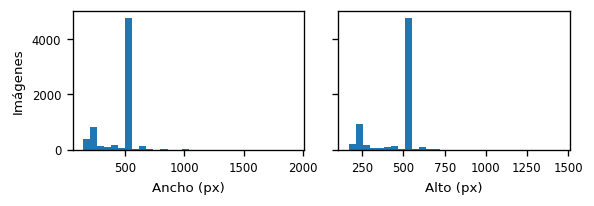

In [35]:
def img_size(path):
    # PIL lee solo el encabezado del archivo, sin decodificar los píxeles
    with Image.open(path) as im:
        return im.size


with ThreadPoolExecutor(8) as ex:
    df["width"], df["height"] = zip(*ex.map(img_size, df.path))

print(f"Resolución mínima: {df.width.min()}x{df.height.min()} | mediana: {int(df.width.median())}x"
      f"{int(df.height.median())} | máxima: {df.width.max()}x{df.height.max()}")
print(f"Imágenes de 512x512: {((df.width == 512) & (df.height == 512)).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(5, 1.8), sharey=True)
axes[0].hist(df.width, bins=30); axes[0].set_xlabel("Ancho (px)"); axes[0].set_ylabel("Imágenes")
axes[1].hist(df.height, bins=30); axes[1].set_xlabel("Alto (px)")
fig.tight_layout()
save_fig(fig, "fig_resolucion_original")
plt.show()

**Conclusión.** Cerca del 70 % de las imágenes mide 512×512, así que llevarlas a 224×224 es una reducción de unas 2.3 veces por eje. Los tumores ocupan una región grande del corte y siguen siendo visibles a esa resolución, que además es la de entrada de ResNet18 preentrenada en ImageNet. **Sí se puede reducir a 224×224.**

In [36]:
# Mediana, mínimo y máximo del tamaño original por clase
display(df.groupby("label")[["width", "height"]].agg(["median", "min", "max"]).reindex(CLASSES))

width            height           
           median  min   max median  min   max
label                                         
Glioma      512.0  512   512  512.0  512   512
Meningioma  512.0  174  1275  512.0  195  1427
Pituitario  512.0  201  1365  512.0  202  1365
Sano        228.0  150  1920  242.0  168  1446

### 1.5 Relación de aspecto

Una red necesita entradas del mismo tamaño, pero forzar una imagen no cuadrada a 224×224 la **estira**. Se calcula la relación de aspecto (ancho/alto) y la **distorsión** que produciría un redimensionamiento directo: cuánto se estira un eje respecto al otro (0 % = cuadrada). La tabla se desglosa por clase, porque lo importante no es solo cuánto se deforman las imágenes, sino si la deformación se concentra en una clase.

Distorsión por clase con un redimensionamiento directo (% de imágenes):


rango_dist,Cuadrada,≤5%,5–10%,10–20%,>20%
label,,,,,
Glioma,100.0,0.0,0.0,0.0,0.0
Meningioma,91.8,1.5,1.8,2.7,2.2
Pituitario,99.6,0.2,0.1,0.0,0.1
Sano,30.9,14.0,12.9,17.2,25.0
All,80.1,4.0,3.8,5.1,7.0


Figura guardada en /kaggle/working/resultados/figuras/fig_relacion_aspecto.png


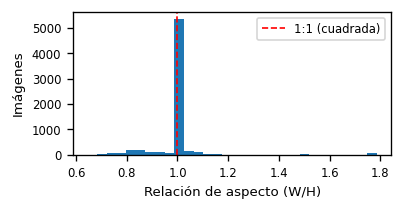

In [37]:
df["aspect_ratio"] = df.width / df.height
df["distorsion"] = np.maximum(df.aspect_ratio, 1 / df.aspect_ratio) - 1   # 0 = cuadrada
df["rango_dist"] = pd.cut(df.distorsion, [-0.001, 0.0, 0.05, 0.10, 0.20, np.inf],
                          labels=["Cuadrada", "≤5%", "5–10%", "10–20%", ">20%"])

print("Distorsión por clase con un redimensionamiento directo (% de imágenes):")
display(pd.crosstab(df.label, df.rango_dist, margins=True, normalize="index").mul(100).round(1))

fig, ax = plt.subplots(figsize=(3.4, 1.8))
ax.hist(df.aspect_ratio, bins=30); ax.axvline(1, color="r", ls="--", lw=1, label="1:1 (cuadrada)")
ax.set_xlabel("Relación de aspecto (W/H)"); ax.set_ylabel("Imágenes"); ax.legend()
fig.tight_layout()
save_fig(fig, "fig_relacion_aspecto")
plt.show()

**Conclusión: hay un sesgo de formato ligado a la clase.** Las clases tumorales son casi 100 % cuadradas, mientras que solo el ~31 % de las imágenes *Sano* lo son y ~25 % se estiraría más de un 20 %. Con un redimensionamiento directo, el modelo podría aprender "cerebro deformado → Sano" en lugar de la ausencia de tumor. En imágenes médicas se ha documentado que modelos con alta precisión aprenden la fuente de la imagen y no la enfermedad. Las métricas en test, que tiene el mismo sesgo, no lo detectarían.

**Decisión:** recortar cada imagen a la caja que contiene el cerebro, completar con negro hasta un cuadrado y solo entonces redimensionar (sección 1.6).

### 1.6 Carga en memoria con recorte y *padding*

El dataset completo cabe en RAM en escala de grises (6597 × 224 × 224 bytes ≈ 331 MB). Cargarlo una sola vez evita leer y decodificar los archivos en cada época, que sería el cuello de botella del entrenamiento.

Cada imagen se procesa así:

1. **Escala de grises:** las MRI no tienen color, solo intensidad, y los tres canales RGB del JPG son prácticamente iguales. Un solo canal permite que el umbral del paso 2 trabaje sobre un valor por píxel y reduce la memoria a la tercera parte (331 MB en lugar de ~1 GB). El canal se replica a tres justo antes de entrar a la red (sección 2), porque ResNet18 fue preentrenada con imágenes RGB; la CNN propia recibe la misma entrada para que la comparación sea justa.
2. **Recorte al cerebro:** el fondo de la MRI es casi negro (intensidad cercana a 0) y el cerebro y el cráneo son más claros. Se toma la caja más pequeña que contiene todos los píxeles con intensidad > 20 y se descarta lo que queda fuera. El recorte no modifica ningún píxel, solo elimina filas y columnas del borde; si se equivoca, lo esperable es que recorte de menos (por texto o ruido claro fuera del cerebro), no que corte anatomía. Así todas las clases quedan encuadradas igual.
3. ***Padding* negro a cuadrado:** se centra el recorte en un lienzo negro cuadrado. Se agrega fondo en lugar de estirar la imagen, de modo que el redimensionamiento no deforma la anatomía.
4. **Redimensionamiento bilineal a 224×224:** todas las imágenes de un *batch* deben tener el mismo tamaño, y 224×224 es la resolución de entrada de ResNet18. Como la imagen ya es cuadrada, ambos ejes se reducen en la misma proporción.

La celda siguiente valida que el cerebro conserva su forma, comparando su relación de aspecto antes y después del procesamiento.

In [38]:
def load_image(path, thr=20):
    img = np.asarray(Image.open(path).convert("L"))

    # Caja delimitadora del cerebro (píxeles por encima del umbral del fondo)
    ys, xs = np.where(img > thr)
    if len(ys) > 0:
        img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]  # si la imagen fuera toda negra, no se recorta

    # Padding negro centrado para que el recorte sea cuadrado
    h, w = img.shape
    side = max(h, w)
    canvas = np.zeros((side, side), dtype=np.uint8)
    y_off, x_off = (side - h) // 2, (side - w) // 2
    canvas[y_off:y_off + h, x_off:x_off + w] = img

    img_resized = Image.fromarray(canvas).resize((CFG["img_size"], CFG["img_size"]), Image.BILINEAR)
    return np.asarray(img_resized, dtype=np.uint8)


t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    IMAGES = np.stack(list(ex.map(load_image, df.path)))  # [N, H, W] uint8
LABELS = df.y.values

print(f"Imágenes en RAM: {IMAGES.shape} | Memoria: {IMAGES.nbytes / 1e6:.1f} MB | "
      f"Tiempo: {time.time() - t0:.1f} s")

Imágenes en RAM: (6597, 224, 224) | Memoria: 331.0 MB | Tiempo: 15.8 s


**Validación del recorte.** Se compara la relación de aspecto (ancho/alto) de la caja que encierra el cerebro en la imagen original y en la procesada. Si el procesamiento no deforma la anatomía, ambas deben ser casi iguales. Se reporta la diferencia mediana y máxima, cuántas imágenes cambian más de un 5 %, y se muestran las imágenes originalmente menos cuadradas antes y después del procesamiento.


--- RESULTADOS DE VALIDACIÓN GEOMÉTRICA DE LA ANATOMÍA ---
Cambio de forma del cerebro (distorsión anatómica real):
  - Distorsión mediana: 0.344%
  - Distorsión máxima: 32.906%
  - Imágenes con distorsión > 5%: 776 de 6597

¡ÉXITO! El cerebro conserva su forma real (distorsión mediana por debajo del 2%).
Figura guardada en /kaggle/working/resultados/figuras/distorsion_geometrica.png


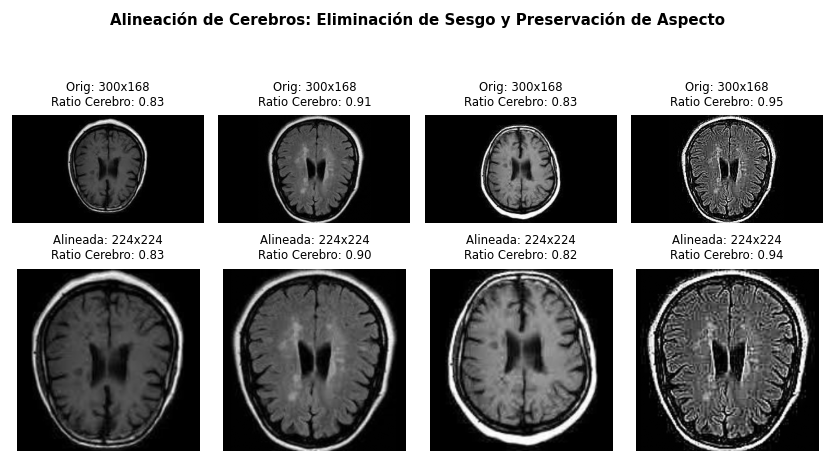

In [39]:
def brain_ratio(arr, thr=20):
    # Relación de aspecto (W/H) de la caja delimitadora que encierra los píxeles del cerebro
    ys, xs = np.where(arr > thr)
    if len(ys) == 0 or len(xs) == 0:
        return 1.0
    return (xs.max() - xs.min() + 1) / (ys.max() - ys.min() + 1)

# 1) Forma del cerebro en la imagen original y en la procesada; el error relativo mide la deformación
orig_brain = np.array([brain_ratio(np.asarray(Image.open(p).convert("L"))) for p in df.path])
desp_brain = np.array([brain_ratio(im) for im in IMAGES])
err_brain = np.abs(desp_brain / orig_brain - 1)

print(f"\n--- RESULTADOS DE VALIDACIÓN GEOMÉTRICA DE LA ANATOMÍA ---")
print(f"Cambio de forma del cerebro (distorsión anatómica real):")
print(f"  - Distorsión mediana: {np.median(err_brain):.3%}")
print(f"  - Distorsión máxima: {err_brain.max():.3%}")
print(f"  - Imágenes con distorsión > 5%: {(err_brain > 0.05).sum()} de {len(err_brain)}")

# Criterio de aceptación: la imagen típica cambia de forma menos de un 2 %
if np.median(err_brain) < 0.02:
    print("\n¡ÉXITO! El cerebro conserva su forma real (distorsión mediana por debajo del 2%).")
else:
    print("\nADVERTENCIA: Se detectó una distorsión significativa en la anatomía del cerebro.")

# 2) Las 4 imágenes originalmente más anchas: arriba la original, abajo la procesada
worst_orig_idx = df.nlargest(4, "aspect_ratio").index
fig, axes = plt.subplots(2, 4, figsize=(7, 3.6))
for j, idx_val in enumerate(worst_orig_idx):
    row = df.loc[idx_val]
    pos = df.index.get_loc(idx_val)
    axes[0, j].imshow(Image.open(row.path).convert("L"), cmap="gray")
    axes[0, j].set_title(f"Orig: {row.width}x{row.height}\nRatio Cerebro: {orig_brain[pos]:.2f}", fontsize=7)
    axes[1, j].imshow(IMAGES[pos], cmap="gray")
    axes[1, j].set_title(f"Alineada: 224x224\nRatio Cerebro: {desp_brain[pos]:.2f}", fontsize=7)

for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Alineación de Cerebros: Eliminación de Sesgo y Preservación de Aspecto", y=1.05, fontsize=9, fontweight="bold")
plt.tight_layout()
save_fig(fig, "distorsion_geometrica")
plt.show()

Para comprobarlo se muestran las 8 imágenes con mayor cambio medido, con la caja del recorte en rojo sobre la original, y el porcentaje de imágenes con cambio > 5 % por clase.

Figura guardada en /kaggle/working/resultados/figuras/fig_peores_recortes.png


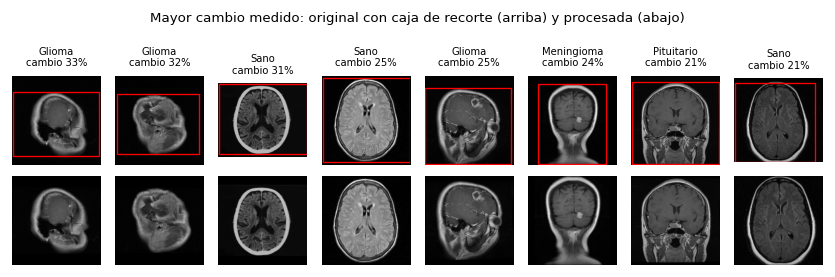

Imágenes con cambio > 5 % por clase (%):


Glioma        15.0
Meningioma    13.3
Pituitario    15.3
Sano           3.6
dtype: float64

In [40]:
# Las 8 imágenes con mayor cambio de forma medido: original con la caja del recorte (rojo) y procesada
worst = np.argsort(-err_brain)[:8]
fig, axes = plt.subplots(2, len(worst), figsize=(7, 2.4))
for j, pos in enumerate(worst):
    orig = np.asarray(Image.open(df.path.iloc[pos]).convert("L"))
    ys, xs = np.where(orig > 20)
    axes[0, j].imshow(orig, cmap="gray", vmin=0, vmax=255)
    if len(ys) > 0:
        axes[0, j].add_patch(plt.Rectangle((xs.min(), ys.min()), xs.max() - xs.min(), ys.max() - ys.min(),
                                           fill=False, ec="r", lw=0.8))
    axes[0, j].set_title(f"{df.label.iloc[pos]}\ncambio {err_brain[pos]:.0%}", fontsize=6)
    axes[1, j].imshow(IMAGES[pos], cmap="gray", vmin=0, vmax=255)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Mayor cambio medido: original con caja de recorte (arriba) y procesada (abajo)", fontsize=8)
plt.tight_layout()
save_fig(fig, "fig_peores_recortes")
plt.show()

# ¿El cambio se concentra en alguna clase?
print("Imágenes con cambio > 5 % por clase (%):")
display(pd.Series(err_brain > 0.05).groupby(df.label.values).mean().mul(100).round(1).reindex(CLASSES))

**Conclusión.** En las 8 imágenes con mayor cambio medido el recorte **no corta anatomía**: la caja roja contiene siempre la cabeza completa y el cerebro procesado se ve entero y sin estirar. Ocurre lo contrario: la caja es más grande que la cabeza porque incluye ruido tenue del fondo (apenas por encima del umbral de 20) o el cuello. Al reducir a 224×224 ese ruido se promedia por debajo del umbral, la caja medida después es más pequeña y el porcentaje de cambio sobreestima la deformación. El recorte es correcto.

**Limitación.** En esas imágenes la cabeza ocupa algo menos del cuadro. Este margen extra es más frecuente en las clases tumorales (13–15 % de las imágenes) que en *Sano* (3.6 %), de modo que queda una diferencia de encuadre pequeña entre clases, mucho menor que el estiramiento que se corrigió. Podría eliminarse suavizando la imagen antes de aplicar el umbral, para que el ruido no entre en la caja.

### 1.7 Balance de clases y ejemplos

,imágenes,porcentaje
label,,
Glioma,1620,24.6
Meningioma,1531,23.2
Pituitario,1740,26.4
Sano,1706,25.9


Figura guardada en /kaggle/working/resultados/figuras/fig_ejemplos_dataset.png


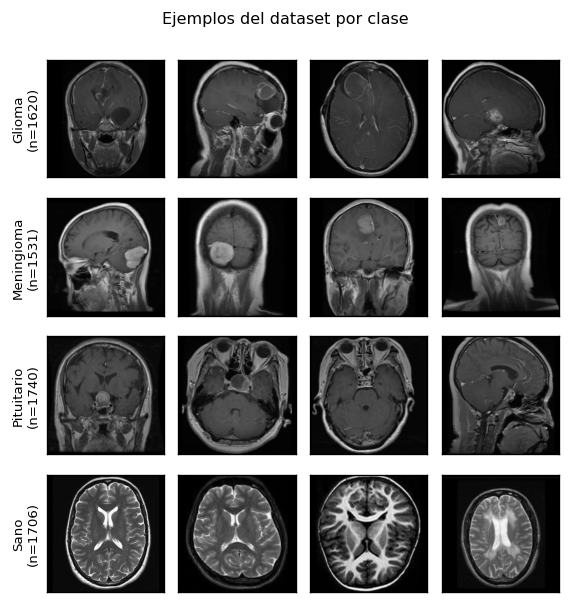

In [41]:
# Distribución de clases: número y porcentaje de imágenes por clase
counts = df.label.value_counts().reindex(CLASSES)
display(counts.to_frame("imágenes").assign(porcentaje=lambda t: (100 * t["imágenes"] / t["imágenes"].sum()).round(1)))

# Cuadrícula de ejemplos ya procesados
rng = np.random.default_rng(0)
n_ex = 4
fig, axes = plt.subplots(len(CLASSES), n_ex, figsize=(n_ex * 1.2, len(CLASSES) * 1.25))
for r, cls in enumerate(CLASSES):
    idx = rng.choice(np.where(df.label.values == cls)[0], n_ex, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(IMAGES[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(f"{cls}\n(n={counts[cls]})")
fig.suptitle("Ejemplos del dataset por clase", y=1.0)
fig.tight_layout()
save_fig(fig, "fig_ejemplos_dataset")
plt.show()

### 1.8 Qué decidimos a partir de la exploración

| Hallazgo | Decisión |
|---|---|
| 426 duplicados exactos (6.1 %) | Eliminarlos antes de partir los datos, para evitar fuga entre train y test. |
| ~70 % de las imágenes en 512×512; los tumores siguen siendo visibles a 224×224 (ejemplos en 1.7) | Reducir a 224×224: pierde poco detalle y coincide con la entrada de ResNet18. |
| Las MRI no tienen color: los tres canales RGB son prácticamente iguales | Cargar en escala de grises (331 MB en RAM) y replicar a 3 canales al entrar a la red. |
| Las imágenes Sano no son cuadradas (sesgo de formato ligado a la clase) | Recorte al cerebro + padding antes de redimensionar. |
| Distorsión mediana del recorte: 0.34 %; 776 imágenes cambian > 5 % (sección 1.6) | El recorte no corta anatomía: el cambio medido viene de ruido de fondo incluido en la caja. Limitación: ese margen extra es más frecuente en las clases tumorales (13–15 %) que en Sano (3.6 %). |
| Clases balanceadas (23–26 % cada una) | Partición estratificada, pérdida sin ponderar; se reporta F1 macro además de accuracy. |
| ~6600 imágenes: pocas para entrenar una red profunda desde cero | Transfer learning (ResNet18 preentrenada) y data augmentation; una CNN propia entrenada desde cero sirve como referencia. |

## 2. Pipeline de datos

**Partición.** Las 6597 imágenes se dividen en tres conjuntos con funciones distintas:

* **Entrenamiento (70 %):** con estas imágenes la red ajusta sus pesos.
* **Validación (15 %):** no se usa para ajustar pesos. Al final de cada época se mide el F1 en este conjunto para elegir con qué época quedarse (la de mayor F1 de validación).
* **Prueba (15 %):** se usa una sola vez, al final, para reportar los resultados. Como el modelo nunca la vio ni se usó para tomar decisiones, estima cómo funcionaría con imágenes nuevas.

La partición es **estratificada**: cada conjunto conserva la misma proporción de clases que el dataset completo, para que ninguna clase quede subrepresentada en validación o prueba. Su semilla es fija (`split_seed = 42`), así que todos los experimentos y semillas se evalúan con exactamente las mismas imágenes.

**Preprocesamiento (a todas las imágenes).** Escala de grises → recorte al cerebro → *padding* negro a cuadrado → redimensión a 224×224 (sección 1.6) → valores en [0, 1] → el canal se replica 3 veces → normalización con la media y la desviación estándar de ImageNet. ResNet18 se preentrenó con imágenes RGB en esa escala; entregarle las imágenes en la misma escala permite aprovechar sus filtros preentrenados. La CNN propia recibe exactamente la misma entrada, para que la comparación sea justa.

***Data augmentation* (solo en entrenamiento).** En cada época, cada imagen de entrenamiento se modifica ligeramente al azar, de modo que la red no ve dos veces exactamente la misma imagen. No se crean imágenes nuevas ni se agrega información (no hay pacientes ni tumores nuevos): en cada época se usan las mismas 4617 imágenes, pero con más variedad, lo que reduce el sobreajuste. Las transformaciones son pequeñas para que la imagen siga siendo una MRI plausible:

* **Volteo horizontal** (probabilidad 0.5): el cerebro es aproximadamente simétrico entre hemisferios y un tumor puede aparecer en cualquiera de los dos. No se usa volteo vertical, porque una MRI nunca aparece de cabeza.
* **Rotación ±10°, traslación ±5 % y escala 0.9–1.1:** simulan diferencias en la posición de la cabeza del paciente dentro del equipo.
* **Brillo y contraste ±20 %:** simulan diferencias entre equipos y protocolos de adquisición.

Validación y prueba no se modifican, para medir el desempeño sobre las imágenes reales.

In [42]:
val_frac, test_frac = CFG["split"][1], CFG["split"][2]
all_idx = np.arange(len(df))
train_idx, rest_idx = train_test_split(all_idx, test_size=val_frac + test_frac, stratify=LABELS,
                                       random_state=CFG["split_seed"])
val_idx, test_idx = train_test_split(rest_idx, test_size=test_frac / (val_frac + test_frac),
                                     stratify=LABELS[rest_idx], random_state=CFG["split_seed"])
SPLITS = {"train": train_idx, "val": val_idx, "test": test_idx}

split_table = pd.DataFrame({name: pd.Series(LABELS[idx]).map(dict(enumerate(CLASSES))).value_counts()
                            for name, idx in SPLITS.items()}).reindex(CLASSES)
split_table.loc["Total"] = split_table.sum()
display(split_table)

,train,val,test
Glioma,1134,243,243
Meningioma,1071,230,230
Pituitario,1218,261,261
Sano,1194,256,256
Total,4617,990,990


**Resultado.** 4617 imágenes de entrenamiento, 990 de validación y 990 de prueba; cada conjunto mantiene la misma proporción de clases (tabla anterior).

Figura guardada en /kaggle/working/resultados/figuras/fig_augmentation.png


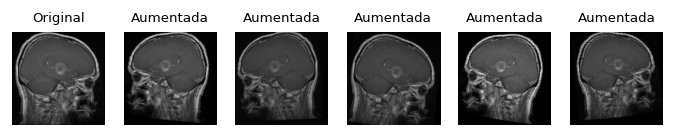

In [43]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # estadísticas de ImageNet

train_aug = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])


def to_model_input(x_uint8):
    # [1, H, W] uint8 -> [3, H, W] float normalizado
    x = x_uint8.float().div(255).repeat(3, 1, 1)
    return T.functional.normalize(x, MEAN, STD)


class MRIDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices, self.augment = indices, augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = torch.from_numpy(IMAGES[j]).unsqueeze(0)  # [1, H, W]
        if self.augment:
            x = train_aug(x)
        return to_model_input(x), int(LABELS[j])


def make_loader(split, augment=False, seed=0):
    train = split == "train"
    return DataLoader(MRIDataset(SPLITS[split], augment=augment), batch_size=CFG["batch_size"],
                      shuffle=train, drop_last=train, num_workers=CFG["num_workers"],
                      pin_memory=device.type == "cuda", persistent_workers=CFG["num_workers"] > 0,
                      generator=torch.Generator().manual_seed(seed))


# Visualización del data augmentation sobre una misma imagen
i0 = train_idx[0]
x0 = torch.from_numpy(IMAGES[i0]).unsqueeze(0)
fig, axes = plt.subplots(1, 6, figsize=(7, 1.4))
axes[0].imshow(x0[0], cmap="gray", vmin=0, vmax=255); axes[0].set_title("Original")
torch.manual_seed(0)
for ax in axes[1:]:
    ax.imshow(train_aug(x0)[0], cmap="gray", vmin=0, vmax=255); ax.set_title("Aumentada")
for ax in axes:
    ax.axis("off")
save_fig(fig, "fig_augmentation")
plt.show()

## 3. Arquitecturas

**A. CNN.** Cinco bloques `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2` con 32, 64, 128, 256 y 512 filtros. Cada bloque duplica los canales y reduce la resolución a la mitad (224 → 7). Le siguen *Global Average Pooling*, *Dropout* (p = 0.5) y una capa lineal de 4 salidas. El diseño sigue el patrón de VGG: filtros pequeños de 3×3 y, en cada bloque, el doble de filtros y la mitad de resolución. Así los primeros bloques detectan patrones simples (bordes, texturas) y los últimos combinan esos patrones en formas más complejas sobre una región más amplia de la imagen. Con cinco reducciones a la mitad, 224 píxeles quedan en 7, un mapa pequeño que resume toda la imagen. BatchNorm estabiliza el entrenamiento desde cero; GAP y Dropout reducen el número de parámetros (1.6 M) y el sobreajuste.

**B/C. ResNet18 con *fine-tuning*.** ResNet18 preentrenada en ImageNet. Se reemplaza la última capa (1000 clases) por una de 4 salidas y se reentrena toda la red con una tasa de aprendizaje baja (1e-4), para adaptar los filtros preentrenados al dominio de MRI sin destruirlos. Ajustar toda la red, en lugar de usarla solo como extractor de características fijo, suele dar mejores resultados al transferir a una tarea nueva.

**¿Por qué ResNet18?** 

* **Capacidad adecuada al tamaño del dataset:** con 11.2 M de parámetros (11.7 M en la versión original de 1000 clases) es mucho más liviana que VGG16 (138 M) o AlexNet (61 M), lo que reduce el riesgo de sobreajuste con ~4600 imágenes de entrenamiento. En imágenes médicas, las arquitecturas pequeñas preentrenadas obtienen resultados comparables a las grandes.
* **Costo computacional:** 1.8 GFLOPs por imagen, frente a 15.5 de VGG16, lo que permite completar las 15 corridas (3 experimentos × 5 semillas) en una GPU T4.
* **Entrenamiento estable:** las conexiones residuales facilitan el flujo del gradiente y permiten ajustar todas las capas sin degradar el entrenamiento. LeNet y AlexNet, en cambio, no usan normalización por lotes y han sido superadas en precisión por las arquitecturas posteriores.
* **Coherencia con el preprocesamiento:** su resolución nativa (224×224) coincide con la elegida en la sección 1.

**Limitación y trabajo futuro.** No se compararon empíricamente otras arquitecturas livianas vistas en el curso, como EfficientNet-B0 (5.3 M parámetros), MobileNetV2 (3.5 M) o DenseNet121 (8.0 M), que podrían igualar o superar a ResNet18 en este dataset. Una extensión natural es entrenarlas con el mismo protocolo (misma partición, preprocesamiento y semillas) para respaldar la elección con evidencia experimental.

**Limitación del diseño experimental.** La CNN y la ResNet18 con *data augmentation* difieren en dos cosas a la vez: la arquitectura y el preentrenamiento en ImageNet. Si C supera a A, no es posible saber cuánto de la diferencia se debe a la arquitectura y cuánto al preentrenamiento. Separar ambos efectos requeriría entrenar también una ResNet18 desde cero con el mismo protocolo. La comparación B vs. C, en cambio, sí aísla un solo factor: el *data augmentation*.

In [44]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes, channels=(32, 64, 128, 256, 512), dropout=0.5):
        super().__init__()
        blocks, c_in = [], 3
        for c_out in channels:
            blocks.append(nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ))
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_resnet18(n_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model


def n_params(model):
    # Número de parámetros entrenables de la red
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ------------------------------------------------------------------------------------------
EXPERIMENTS = [
    {"id": "A", "name": "CNN propia", "build": lambda: SimpleCNN(len(CLASSES)), "lr": 1e-3,
     "augment": True, "cam_layer": lambda m: m.features[-1][2]},
    {"id": "B", "name": "ResNet18 FT (sin aug.)", "build": lambda: build_resnet18(len(CLASSES)), "lr": 1e-4,
     "augment": False, "cam_layer": lambda m: m.layer4[-1]},
    {"id": "C", "name": "ResNet18 FT (con aug.)", "build": lambda: build_resnet18(len(CLASSES)), "lr": 1e-4,
     "augment": True, "cam_layer": lambda m: m.layer4[-1]},
]
EXP = {e["id"]: e for e in EXPERIMENTS}  # índice por letra: EXP["C"] devuelve la ficha de C

# Crea cada red una vez solo para contar sus parámetros (no se entrena aquí)
for e in EXPERIMENTS:
    e["params"] = n_params(e["build"]())
    print(f"{e['id']}: {e['name']:<24} {e['params'] / 1e6:5.2f} M parámetros")

A: CNN propia                1.57 M parámetros
B: ResNet18 FT (sin aug.)   11.18 M parámetros
C: ResNet18 FT (con aug.)   11.18 M parámetros


## 4. Entrenamiento

Cada experimento se entrena 5 veces, una por semilla: 15 corridas en total. En cada corrida:

1. Se fija la semilla y se crea una red nueva con la ficha del experimento.
2. Se repiten 25 épocas:
   * **Entrenamiento:** la red recorre las 4617 imágenes de entrenamiento en lotes de 32 y ajusta sus pesos para reducir la pérdida.
   * **Validación:** se mide el F1 macro en las 990 imágenes de validación, sin ajustar pesos.
   * Si el F1 de validación mejoró, se guarda una copia de los pesos. No se detiene antes de tiempo: se completan las 25 épocas.
3. Se recuperan los pesos de la mejor época y se evalúan **una sola vez** en las 990 imágenes de prueba.
4. Se guardan en disco los pesos, el historial por época y las predicciones en prueba.

**Configuración.**

- **Función de pérdida:** entropía cruzada, estándar en clasificación multiclase.
- **Optimizador:** AdamW con `weight_decay = 1e-4`, tasa de aprendizaje 1e-3 para la CNN desde cero y 1e-4 para el *fine-tuning*, y decaimiento coseno a lo largo de las épocas: la tasa empieza alta para avanzar rápido y baja gradualmente para afinar los pesos al final.
- **Selección de la mejor época (sin corte anticipado):** se entrenan siempre las 25 épocas y se conservan los pesos de la época con mayor **F1 macro en validación**. En corridas previas (carpeta `respaldos/`), un *early stopping* con paciencia de 5 y luego de 10 épocas detuvo la CNN propia demasiado pronto en algunas semillas (por ejemplo, en la época 15 con 83 % de exactitud), porque su F1 de validación oscila mucho de una época a otra. Como la mayoría de las corridas ya llegaba a 21–25 épocas, entrenar siempre las 25 cuesta poco y deja el protocolo igual para todos los experimentos.
- **Precisión mixta (AMP):** en GPU, parte de los cálculos se hacen en 16 bits en lugar de 32, lo que acelera el entrenamiento sin afectar la exactitud de forma apreciable.
- **Métricas:** *accuracy*, y *precision*, *recall* y F1 en promedio **macro**, que pesa todas las clases por igual. En diagnóstico se presta atención especial al *recall* por clase (sensibilidad), porque un tumor clasificado como sano (falso negativo) es el error más costoso.

**Reproducibilidad.** Las semillas fijan la inicialización, el orden de los datos y el *augmentation*, pero `cudnn.benchmark = True` elige en cada ejecución el algoritmo de convolución más rápido, por lo que repetir una corrida con la misma semilla puede dar resultados ligeramente distintos (décimas de punto porcentual). Por eso se reporta la variación entre semillas y no el valor de una sola corrida.

In [45]:
def compute_metrics(y, probs):
    # Métricas a partir de las etiquetas reales (y) y las probabilidades predichas (probs)
    pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    _, r_cls, _, _ = precision_recall_fscore_support(y, pred, labels=range(len(CLASSES)), average=None,
                                                     zero_division=0)
    out = {"acc": accuracy_score(y, pred), "prec": p, "rec": r, "f1": f1}
    out.update({f"rec_{c}": v for c, v in zip(CLASSES, r_cls)})
    return out

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    # Recorre un conjunto completo una vez. Con optimizer entrena (ajusta pesos); sin él solo evalúa.
    train = optimizer is not None
    model.train(train)
    total_loss, ys, ps = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                # Retropropagación: calcula cómo cambiar cada peso para reducir la pérdida y lo aplica
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            ys.append(y.cpu())
            ps.append(logits.float().softmax(1).detach().cpu())
    y, probs = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return total_loss / len(y), y, probs

def train_experiment(exp, seed):
    # Una corrida completa: entrena el experimento 'exp' con la semilla 'seed' y lo evalúa en prueba
    tag = f"{exp['id']}_s{seed}"
    result_file = OUT_DIR / f"{tag}.json"
    if result_file.exists():  
        print(f"[{tag}] ya existe, se carga desde disco")
        return json.loads(result_file.read_text())

    # 1) Semilla, red nueva, datos, pérdida, optimizador y decaimiento coseno de la tasa de aprendizaje
    set_seed(seed)
    model = exp["build"]().to(device)
    train_loader = make_loader("train", augment=exp["augment"], seed=seed)
    val_loader, test_loader = make_loader("val"), make_loader("test")
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=exp["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    # 2) Ciclo de épocas: entrenar, validar y guardar los pesos de la mejor época según el F1 de validación
    history, best_f1, best_epoch, bad_epochs, t_start = [], -1.0, 0, 0, time.time()
    for epoch in range(1, CFG["epochs"] + 1):
        t0 = time.time()
        tr_loss, y_tr, p_tr = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, y_va, p_va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        m_tr, m_va = compute_metrics(y_tr, p_tr), compute_metrics(y_va, p_va)
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                        "train_acc": m_tr["acc"], "val_acc": m_va["acc"], "val_f1": m_va["f1"]})
        print(f"[{tag}] época {epoch:2d} | loss train {tr_loss:.3f} val {va_loss:.3f} | "
              f"acc train {m_tr['acc']:.3f} val {m_va['acc']:.3f} | F1 val {m_va['f1']:.3f} | "
              f"{time.time() - t0:.0f}s", flush=True)
        if m_va["f1"] > best_f1:
            best_f1, best_epoch, bad_epochs = m_va["f1"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if CFG["patience"] and bad_epochs >= CFG["patience"]:  # con patience=None nunca se corta
                print(f"[{tag}] early stopping en la época {epoch}", flush=True)
                break
    train_time = time.time() - t_start

    # 3) Se recuperan los pesos de la mejor época y se evalúan en validación y, una sola vez, en prueba
    model.load_state_dict(best_state)
    _, y_va, p_va = run_epoch(model, val_loader, criterion)
    _, y_te, p_te = run_epoch(model, test_loader, criterion)
    res = {"exp": exp["id"], "seed": seed, "best_epoch": best_epoch, "epochs_run": len(history),
           "train_time_s": train_time,
           **{f"val_{k}": float(v) for k, v in compute_metrics(y_va, p_va).items()},
           **{f"test_{k}": float(v) for k, v in compute_metrics(y_te, p_te).items()},
           "history": history}
    # 4) Se guardan pesos, predicciones en prueba y resultados
    torch.save(best_state, CKPT_DIR / f"{tag}.pt")
    np.save(OUT_DIR / f"{tag}_test_probs.npy", p_te)
    result_file.write_text(json.dumps(res))
    print(f"[{tag}] mejor época {best_epoch} | test acc {res['test_acc']:.4f} F1 {res['test_f1']:.4f} | "
          f"{train_time / 60:.1f} min", flush=True)
    return res

In [46]:
# Entrena los 3 experimentos × 5 semillas (15 corridas, ~55-60 min en una GPU T4)
results = [train_experiment(exp, seed) for exp in EXPERIMENTS for seed in CFG["seeds"]]
res_df = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in results])
res_df.to_csv(OUT_DIR / "resultados_por_corrida.csv", index=False)
display(res_df[["exp", "seed", "best_epoch", "epochs_run", "val_f1", "test_acc", "test_f1"]].round(4))

[A_s0] época  1 | loss train 0.845 val 0.833 | acc train 0.637 val 0.596 | F1 val 0.593 | 23s
[A_s0] época  2 | loss train 0.684 val 0.470 | acc train 0.729 val 0.818 | F1 val 0.819 | 9s
[A_s0] época  3 | loss train 0.586 val 0.443 | acc train 0.772 val 0.838 | F1 val 0.838 | 9s
[A_s0] época  4 | loss train 0.551 val 0.534 | acc train 0.790 val 0.782 | F1 val 0.777 | 9s
[A_s0] época  5 | loss train 0.509 val 0.540 | acc train 0.809 val 0.779 | F1 val 0.772 | 9s
[A_s0] época  6 | loss train 0.484 val 0.457 | acc train 0.814 val 0.802 | F1 val 0.783 | 9s
[A_s0] época  7 | loss train 0.443 val 1.476 | acc train 0.836 val 0.632 | F1 val 0.562 | 9s
[A_s0] época  8 | loss train 0.423 val 0.983 | acc train 0.846 val 0.689 | F1 val 0.679 | 9s
[A_s0] época  9 | loss train 0.380 val 0.441 | acc train 0.862 val 0.851 | F1 val 0.844 | 9s
[A_s0] época 10 | loss train 0.361 val 1.510 | acc train 0.866 val 0.526 | F1 val 0.463 | 9s
[A_s0] época 11 | loss train 0.361 val 0.390 | acc train 0.861 val 0.

,exp,seed,best_epoch,epochs_run,val_f1,test_acc,test_f1
0,A,0,23,25,0.9554,0.9323,0.9303
1,A,1,23,25,0.9512,0.9374,0.9361
2,A,2,24,25,0.9492,0.9414,0.9399
3,A,3,25,25,0.9545,0.9384,0.9370
4,A,4,25,25,0.9554,0.9475,0.9464
5,B,0,23,25,0.9886,0.9848,0.9846
6,B,1,24,25,0.9885,0.9889,0.9888
7,B,2,17,25,0.9897,0.9848,0.9847
8,B,3,12,25,0.9906,0.9859,0.9857
9,B,4,18,25,0.9927,0.9889,0.9886


## 5. Resultados cuantitativos

In [47]:
def mean_std(series, pct=True):
    k = 100 if pct else 1
    return f"{k * series.mean():.2f} ± {k * series.std(ddof=1):.2f}" if len(series) > 1 else f"{k * series.mean():.2f}"

import glob

# Intentamos usar 'results' de memoria si existe y no está vacío, de lo contrario cargamos desde disco
try:
    if 'results' in globals() and len(results) > 0:
        local_results = results
    else:
        local_results = []
        for path in sorted(glob.glob(str(OUT_DIR / "*_s[0-9].json"))):
            local_results.append(json.loads(Path(path).read_text()))
except Exception as e:
    local_results = []

if len(local_results) > 0:
    res_df = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in local_results])
else:
    res_df = pd.DataFrame(columns=["exp", "seed", "best_epoch", "train_time_s", "test_acc", "test_prec", "test_rec", "test_f1", "val_f1"])

rows = []
for e in EXPERIMENTS:
    if "exp" in res_df.columns:
        r = res_df[res_df["exp"] == e["id"]]
    else:
        r = pd.DataFrame()

    if len(r) > 0:
        rows.append({"Exp.": e["id"], "Modelo": e["name"], "Parámetros (M)": round(e["params"] / 1e6, 2),
                     "Accuracy (%)": mean_std(r["test_acc"]),
                     "Precisión macro (%)": mean_std(r["test_prec"]),
                     "Recall macro (%)": mean_std(r["test_rec"]),
                     "F1 macro (%)": mean_std(r["test_f1"]),
                     "Mejor época": mean_std(r["best_epoch"], pct=False),
                     "Tiempo (min)": mean_std(r["train_time_s"] / 60, pct=False)})

table_main = pd.DataFrame(rows)
if len(table_main) > 0:
    table_main.to_csv(OUT_DIR / "tabla_resultados.csv", index=False)
    print("Tabla principal (test):")
    display(table_main)
else:
    print("ADVERTENCIA: No hay resultados de entrenamiento completados para mostrar en la tabla.")

if len(res_df) > 0 and "exp" in res_df.columns:
    table_cls = pd.DataFrame({e["name"]: {c: mean_std(res_df[res_df["exp"] == e["id"]][f"test_rec_{c}"]) for c in CLASSES}
                              for e in EXPERIMENTS if len(res_df[res_df["exp"] == e["id"]]) > 0}).T
    table_cls.to_csv(OUT_DIR / "tabla_recall_por_clase.csv")
    print("\nRecall (sensibilidad) por clase en test (%):")
    display(table_cls)

    # Mejor experimento (F1 de validación promedio) y su mejor semilla
    best_exp_id = res_df.groupby("exp").val_f1.mean().idxmax()
    best_seed_of = {e["id"]: int(res_df[res_df["exp"] == e["id"]].sort_values("val_f1").iloc[-1].seed) for e in EXPERIMENTS if len(res_df[res_df["exp"] == e["id"]]) > 0}
    best_seed = best_seed_of.get(best_exp_id, 0)
    print(f"\nMejor experimento según validación: {best_exp_id} ({EXP[best_exp_id]['name']}), semilla {best_seed}")

Tabla principal (test):


,Exp.,Modelo,Parámetros (M),Accuracy (%),Precisión macro (%),Recall macro (%),F1 macro (%),Mejor época,Tiempo (min)
0,A,CNN propia,1.57,93.94 ± 0.56,93.83 ± 0.57,93.79 ± 0.59,93.79 ± 0.59,24.00 ± 1.00,3.81 ± 0.09
1,B,ResNet18 FT (sin aug.),11.18,98.67 ± 0.21,98.67 ± 0.20,98.64 ± 0.21,98.65 ± 0.21,18.80 ± 4.87,3.54 ± 0.10
2,C,ResNet18 FT (con aug.),11.18,98.73 ± 0.26,98.73 ± 0.26,98.73 ± 0.28,98.72 ± 0.27,13.40 ± 6.07,3.86 ± 0.02



Recall (sensibilidad) por clase en test (%):


,Glioma,Meningioma,Pituitario,Sano
CNN propia,92.51 ± 2.09,89.04 ± 0.99,95.94 ± 1.17,97.66 ± 0.39
ResNet18 FT (sin aug.),99.84 ± 0.23,96.87 ± 0.36,98.62 ± 0.21,99.22 ± 0.48
ResNet18 FT (con aug.),99.51 ± 0.34,98.17 ± 0.84,98.16 ± 0.57,99.06 ± 0.65



Mejor experimento según validación: C (ResNet18 FT (con aug.)), semilla 2


Figura guardada en /kaggle/working/resultados/figuras/fig_curvas_entrenamiento.png


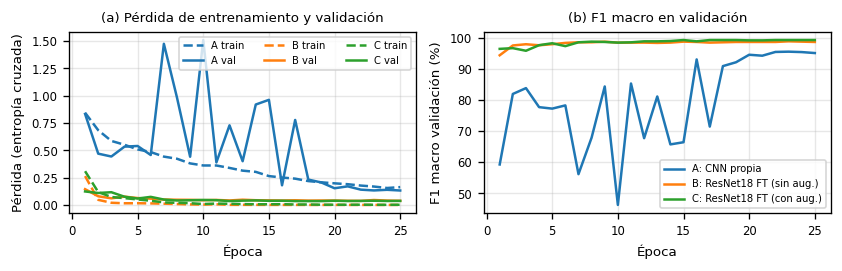

In [48]:
# Curvas de entrenamiento (semilla 0 de cada experimento): pérdida y F1 de validación
colors = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}
hist = {r["exp"]: pd.DataFrame(r["history"]) for r in results if r["seed"] == CFG["seeds"][0]}
fig, axes = plt.subplots(1, 2, figsize=(7, 2.3))
for e in EXPERIMENTS:
    h, c = hist[e["id"]], colors[e["id"]]
    axes[0].plot(h.epoch, h.train_loss, "--", color=c, label=f"{e['id']} train")
    axes[0].plot(h.epoch, h.val_loss, "-", color=c, label=f"{e['id']} val")
    axes[1].plot(h.epoch, 100 * h.val_f1, "-", color=c, label=f"{e['id']}: {e['name']}")
axes[0].set(xlabel="Época", ylabel="Pérdida (entropía cruzada)", title="(a) Pérdida de entrenamiento y validación")
axes[1].set(xlabel="Época", ylabel="F1 macro validación (%)", title="(b) F1 macro en validación")
axes[0].legend(ncol=3, fontsize=6); axes[1].legend(fontsize=6)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, "fig_curvas_entrenamiento")
plt.show()

Figura guardada en /kaggle/working/resultados/figuras/fig_matrices_confusion.png


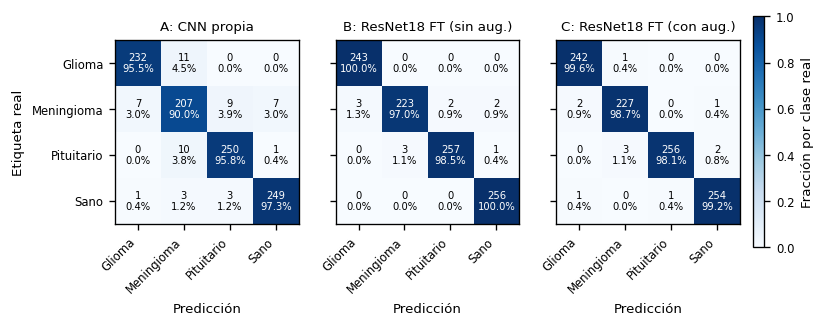

Reporte de clasificación en test — ResNet18 FT (con aug.) (semilla 2):
              precision    recall  f1-score   support

      Glioma     0.9878    0.9959    0.9918       243
  Meningioma     0.9827    0.9870    0.9848       230
  Pituitario     0.9961    0.9808    0.9884       261
        Sano     0.9883    0.9922    0.9903       256

    accuracy                         0.9889       990
   macro avg     0.9887    0.9890    0.9888       990
weighted avg     0.9889    0.9889    0.9889       990



In [49]:
# Matrices de confusión en test (mejor semilla de cada experimento), normalizadas por fila (= recall por clase)
y_test = LABELS[test_idx]
fig, axes = plt.subplots(1, len(EXPERIMENTS), figsize=(7, 2.5))
for ax, e in zip(axes, EXPERIMENTS):
    probs = np.load(OUT_DIR / f"{e['id']}_s{best_seed_of[e['id']]}_test_probs.npy")
    cm = confusion_matrix(y_test, probs.argmax(1), labels=range(len(CLASSES)))
    cm_norm = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]}\n{100 * cm_norm[i, j]:.1f}%", ha="center", va="center", fontsize=6,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES if ax is axes[0] else [])
    ax.set_xlabel("Predicción")
    ax.set_title(f"{e['id']}: {e['name']}")
axes[0].set_ylabel("Etiqueta real")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Fracción por clase real")
save_fig(fig, "fig_matrices_confusion")
plt.show()

best_probs = np.load(OUT_DIR / f"{best_exp_id}_s{best_seed}_test_probs.npy")
print(f"Reporte de clasificación en test — {EXP[best_exp_id]['name']} (semilla {best_seed}):")
print(classification_report(y_test, best_probs.argmax(1), target_names=CLASSES, digits=4))

## 6. Resultados cualitativos

In [50]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model.eval(), None, None
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        self.acts = output
        output.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        # x: [3, H, W] normalizado -> (mapa en [0, 1] de tamaño H×W, probabilidades)
        with torch.enable_grad():
            logits = self.model(x.unsqueeze(0).to(device))
            cls = int(logits.argmax(1))
            self.model.zero_grad(set_to_none=True)
            logits[0, cls].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), logits.softmax(1)[0].detach().cpu().numpy()

    def remove(self):
        self.handle.remove()


def load_model(exp_id, seed):
    model = EXP[exp_id]["build"]().to(device)
    model.load_state_dict(torch.load(CKPT_DIR / f"{exp_id}_s{seed}.pt", map_location=device))
    return model.eval()


def show_cam(ax, j, cam, title, color="black"):
    ax.imshow(IMAGES[j], cmap="gray", vmin=0, vmax=255)
    im = ax.imshow(cam, cmap="jet", alpha=0.35, vmin=0, vmax=1)
    ax.set_title(title, color=color, fontsize=6.5)
    ax.axis("off")
    return im

Errores del mejor modelo en test: 11 de 990
Figura guardada en /kaggle/working/resultados/figuras/fig_cualitativos_gradcam.png


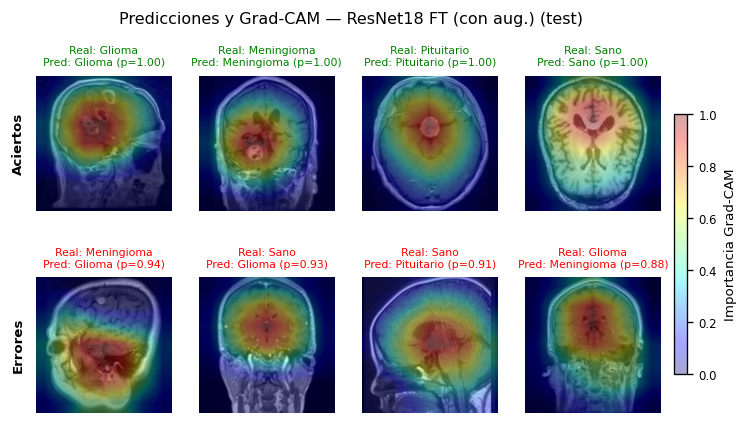

In [51]:
# Aciertos (el más confiable de cada clase) y los 4 errores más confiables del mejor modelo
pred, conf = best_probs.argmax(1), best_probs.max(1)
correct_pos = [np.where((y_test == k) & (pred == k))[0] for k in range(len(CLASSES))]
correct_pos = [pos[conf[pos].argmax()] for pos in correct_pos if len(pos)]
wrong_pos = np.where(pred != y_test)[0]
wrong_pos = wrong_pos[np.argsort(-conf[wrong_pos])][:4]
print(f"Errores del mejor modelo en test: {len(np.where(pred != y_test)[0])} de {len(y_test)}")

model = load_model(best_exp_id, best_seed)
cam_fn = GradCAM(model, EXP[best_exp_id]["cam_layer"](model))
rows_cfg = [("Aciertos", correct_pos), ("Errores", wrong_pos)]
fig, axes = plt.subplots(2, 4, figsize=(7, 4))
for r, (row_name, positions) in enumerate(rows_cfg):
    for c in range(4):
        ax = axes[r, c]
        if c >= len(positions):
            ax.axis("off")
            continue
        j = test_idx[positions[c]]
        cam, probs = cam_fn(to_model_input(torch.from_numpy(IMAGES[j]).unsqueeze(0)))
        k = probs.argmax()
        ok = k == LABELS[j]
        im = show_cam(ax, j, cam, f"Real: {CLASSES[LABELS[j]]}\nPred: {CLASSES[k]} (p={probs[k]:.2f})",
                      color="green" if ok else "red")
    axes[r, 0].text(-0.08, 0.5, row_name, transform=axes[r, 0].transAxes, rotation=90, ha="right",
                    va="center", fontsize=8, fontweight="bold")
cam_fn.remove()
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Importancia Grad-CAM")
fig.suptitle(f"Predicciones y Grad-CAM — {EXP[best_exp_id]['name']} (test)", y=0.98)
save_fig(fig, "fig_cualitativos_gradcam")
plt.show()

Figura guardada en /kaggle/working/resultados/figuras/fig_gradcam_comparacion_modelos.png


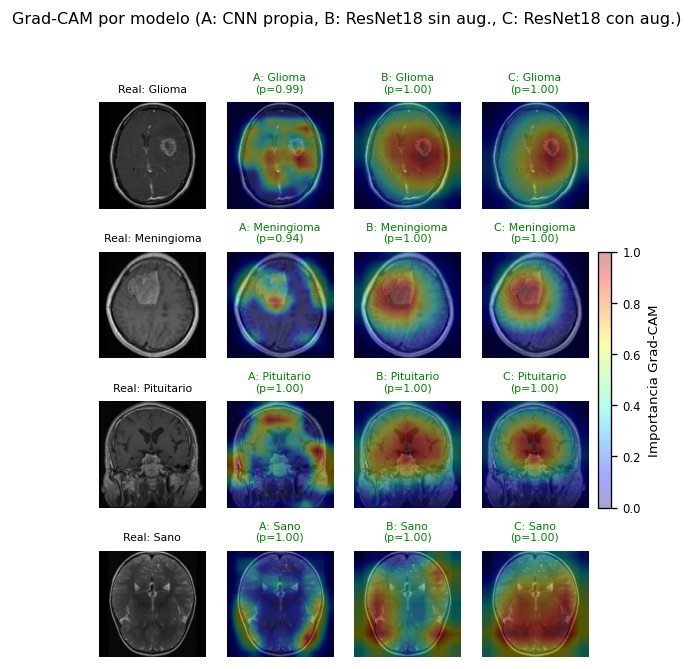

In [52]:
# Comparación entre modelos: las mismas imágenes de test (una por clase) con el Grad-CAM de cada experimento
rng = np.random.default_rng(1)
sample_pos = [rng.choice(np.where(y_test == k)[0]) for k in range(len(CLASSES))]
models_cam = {e["id"]: load_model(e["id"], best_seed_of[e["id"]]) for e in EXPERIMENTS}

fig, axes = plt.subplots(len(sample_pos), 1 + len(EXPERIMENTS), figsize=(5.5, 6.2))
for r, pos in enumerate(sample_pos):
    j = test_idx[pos]
    x = to_model_input(torch.from_numpy(IMAGES[j]).unsqueeze(0))
    axes[r, 0].imshow(IMAGES[j], cmap="gray", vmin=0, vmax=255)
    axes[r, 0].set_title(f"Real: {CLASSES[LABELS[j]]}", fontsize=6.5)
    axes[r, 0].axis("off")
    for c, e in enumerate(EXPERIMENTS, start=1):
        m = models_cam[e["id"]]
        cam_fn = GradCAM(m, e["cam_layer"](m))
        cam, probs = cam_fn(x)
        cam_fn.remove()
        k = probs.argmax()
        im = show_cam(axes[r, c], j, cam, f"{e['id']}: {CLASSES[k]}\n(p={probs[k]:.2f})",
                      color="green" if k == LABELS[j] else "red")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="Importancia Grad-CAM")
fig.suptitle("Grad-CAM por modelo (A: CNN propia, B: ResNet18 sin aug., C: ResNet18 con aug.)", y=0.99)
save_fig(fig, "fig_gradcam_comparacion_modelos")
plt.show()

## 7. Resumen para el informe

Esta celda reúne los números que deben aparecer en el informe (dataset, partición, hiperparámetros y resultados), para que el informe y el notebook coincidan. La siguiente celda descarga figuras y tablas en un `.zip`.

In [53]:
hyper = pd.DataFrame([{
    "Exp.": e["id"], "Modelo": e["name"], "Inicialización": "Aleatoria" if e["id"] == "A" else "ImageNet",
    "Data aug.": "Sí" if e["augment"] else "No", "Optimizador": "AdamW", "LR inicial": e["lr"],
    "Scheduler": "Coseno", "Weight decay": CFG["weight_decay"], "Batch": CFG["batch_size"],
    "Épocas máx.": CFG["epochs"], "Paciencia": CFG["patience"] or "Sin corte", "Entrada": f"{CFG['img_size']}x{CFG['img_size']}",
    "Pérdida": "Entropía cruzada"} for e in EXPERIMENTS])
hyper.to_csv(OUT_DIR / "tabla_hiperparametros.csv", index=False)
display(hyper)

summary = {
    "imagenes_encontradas": int(n_raw), "duplicados_eliminados": int(n_raw - len(df)), "imagenes_finales": int(len(df)),
    "por_clase": counts.to_dict(), "particion": {k: int(len(v)) for k, v in SPLITS.items()},
    "mejor_experimento": f"{best_exp_id} ({EXP[best_exp_id]['name']}), semilla {best_seed}",
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU",
}
(OUT_DIR / "resumen.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nArchivos generados en", OUT_DIR)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and p.suffix in {".png", ".csv", ".json"} and "_s" not in p.stem:
        print("  ", p.relative_to(OUT_DIR))

,Exp.,Modelo,Inicialización,Data aug.,Optimizador,LR inicial,Scheduler,Weight decay,Batch,Épocas máx.,Paciencia,Entrada,Pérdida
0,A,CNN propia,Aleatoria,Sí,AdamW,0.0010,Coseno,0.0001,32,25,Sin corte,224x224,Entropía cruzada
1,B,ResNet18 FT (sin aug.),ImageNet,No,AdamW,0.0001,Coseno,0.0001,32,25,Sin corte,224x224,Entropía cruzada
2,C,ResNet18 FT (con aug.),ImageNet,Sí,AdamW,0.0001,Coseno,0.0001,32,25,Sin corte,224x224,Entropía cruzada


{
  "imagenes_encontradas": 7023,
  "duplicados_eliminados": 426,
  "imagenes_finales": 6597,
  "por_clase": {
    "Glioma": 1620,
    "Meningioma": 1531,
    "Pituitario": 1740,
    "Sano": 1706
  },
  "particion": {
    "train": 4617,
    "val": 990,
    "test": 990
  },
  "mejor_experimento": "C (ResNet18 FT (con aug.)), semilla 2",
  "gpu": "Tesla T4"
}

Archivos generados en /kaggle/working/resultados
   figuras/distorsion_geometrica.png
   figuras/fig_augmentation.png
   figuras/fig_cualitativos_gradcam.png
   figuras/fig_curvas_entrenamiento.png
   figuras/fig_ejemplos_dataset.png
   figuras/fig_gradcam_comparacion_modelos.png
   figuras/fig_matrices_confusion.png
   figuras/fig_peores_recortes.png
   figuras/fig_relacion_aspecto.png
   figuras/fig_resolucion_original.png
   resultados_por_corrida.csv
   resumen.json
   tabla_hiperparametros.csv
   tabla_recall_por_clase.csv
   tabla_resultados.csv


In [54]:
# Descarga figuras y tablas (sin checkpoints) como .zip. Solo funciona en Colab.
export_dir = OUT_DIR.parent / "miniproyecto1_resultados"
shutil.rmtree(export_dir, ignore_errors=True)
shutil.copytree(OUT_DIR, export_dir, ignore=shutil.ignore_patterns("checkpoints", "*.npy"))
zip_path = shutil.make_archive(str(export_dir), "zip", export_dir)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Archivo generado:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>